# INFS4203/7203 Project: Credit Default Classification

**Track 1: Data-oriented project**

Development notebook: exploratory data analysis, preprocessing trials, model comparison,
and hyperparameter tuning. The final chosen pipeline is implemented separately in `main.py`.

Random seed fixed at **42** throughout for reproducibility.

In [7]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

SEED = 42
np.random.seed(SEED)

## 1. Data Loading and Initial Inspection

Load `development.csv` (labelled, used for all model selection/validation) and `test.csv`
(unlabelled, predictions only). Per the project spec, `test.csv` must not inform any
preprocessing or modelling decision — we only load it here to confirm its shape/columns
match expectations.

In [8]:
df = pd.read_csv('development.csv')
df_test = pd.read_csv('test.csv')

print('development.csv shape:', df.shape)
print('test.csv shape:', df_test.shape)

development.csv shape: (24000, 25)
test.csv shape: (6000, 24)


In [9]:
df.head(10)

,client_id,credit_limit,sex,education,marital_status,age,repayment_status_mar,repayment_status_feb,repayment_status_jan,repayment_status_dec,repayment_status_nov,repayment_status_oct,bill_amount_mar,bill_amount_feb,bill_amount_jan,bill_amount_dec,bill_amount_nov,bill_amount_oct,payment_amount_mar,payment_amount_feb,payment_amount_jan,payment_amount_dec,payment_amount_nov,payment_amount_oct,defaulted_next_month
0,22789,160000.0,female,NaN,single,33.0,payment_delayed_2_months,NaN,NaN,NaN,NaN,revolving_credit,161771.0,NaN,NaN,NaN,162681.0,163005.0,NaN,0.0,0.0,6100.0,12300.0,6100.0,no
1,29007,NaN,female,graduate_school,single,34.0,payment_delayed_1_month,NaN,paid_on_time,NaN,NaN,no_balance,0.0,NaN,0.0,0.0,0.0,0.0,53.0,0.0,0.0,0.0,0.0,0.0,no
2,16951,NaN,NaN,NaN,NaN,50.0,NaN,payment_delayed_2_months,revolving_credit,NaN,NaN,revolving_credit,10171.0,8150.0,NaN,8067.0,NaN,8400.0,2.0,1281.0,NaN,294.0,305.0,1000.0,no
3,22281,NaN,female,graduate_school,single,NaN,NaN,NaN,NaN,revolving_credit,NaN,NaN,206879.0,211037.0,215139.0,218513.0,131660.0,NaN,NaN,NaN,NaN,4800.0,NaN,6000.0,yes
4,11347,NaN,female,NaN,NaN,32.0,payment_delayed_1_month,no_balance,paid_on_time,revolving_credit,revolving_credit,no_balance,0.0,0.0,326.0,NaN,-235.0,-235.0,0.0,326.0,NaN,0.0,NaN,NaN,no
5,4103,NaN,NaN,NaN,single,NaN,paid_on_time,NaN,NaN,NaN,paid_on_time,payment_delayed_2_months,NaN,NaN,6649.0,5149.0,NaN,NaN,6959.0,15.0,0.0,NaN,0.0,NaN,yes
6,28655,NaN,NaN,high_school,NaN,33.0,paid_on_time,payment_delayed_2_months,NaN,payment_delayed_2_months,NaN,no_balance,NaN,755.0,44255.0,NaN,-772.0,-772.0,NaN,43500.0,0.0,0.0,NaN,NaN,no
7,26151,50000.0,NaN,university,NaN,NaN,payment_delayed_3_months,payment_delayed_3_months,payment_delayed_2_months,NaN,NaN,payment_delayed_2_months,47904.0,NaN,48602.0,NaN,44837.0,44535.0,2000.0,NaN,NaN,2000.0,2000.0,1500.0,yes
8,15092,360000.0,male,graduate_school,NaN,NaN,revolving_credit,NaN,revolving_credit,revolving_credit,NaN,revolving_credit,120533.0,124530.0,128518.0,134368.0,135626.0,134864.0,NaN,6000.0,NaN,4918.0,NaN,3300.0,no
9,6267,320000.0,NaN,university,single,29.0,revolving_credit,NaN,revolving_credit,revolving_credit,revolving_credit,NaN,324693.0,NaN,325024.0,NaN,297637.0,301575.0,NaN,NaN,11900.0,10503.0,10886.0,10040.0,no


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24000 entries, 0 to 23999
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   client_id             24000 non-null  int64  
 1   credit_limit          14400 non-null  float64
 2   sex                   14400 non-null  object 
 3   education             14400 non-null  object 
 4   marital_status        14400 non-null  object 
 5   age                   14400 non-null  float64
 6   repayment_status_mar  14400 non-null  object 
 7   repayment_status_feb  14400 non-null  object 
 8   repayment_status_jan  14400 non-null  object 
 9   repayment_status_dec  14400 non-null  object 
 10  repayment_status_nov  14400 non-null  object 
 11  repayment_status_oct  14400 non-null  object 
 12  bill_amount_mar       14400 non-null  float64
 13  bill_amount_feb       14400 non-null  float64
 14  bill_amount_jan       14400 non-null  float64
 15  bill_amount_dec    

In [11]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
client_id,24000.0,NaN,NaN,NaN,14973.683417,8641.664947,1.0,7513.75,14966.0,22438.25,30000.0
credit_limit,14400.0,NaN,NaN,NaN,166951.527778,129539.486324,10000.0,50000.0,140000.0,240000.0,1000000.0
sex,14400,2,female,8766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,14400,5,university,6802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital_status,14400,4,single,7699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,14400.0,NaN,NaN,NaN,35.359097,9.179001,21.0,28.0,34.0,41.0,74.0
repayment_status_mar,14400,11,revolving_credit,7002,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_feb,14400,11,revolving_credit,7590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_jan,14400,11,revolving_credit,7537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
repayment_status_dec,14400,10,revolving_credit,7921,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### 1.1 Column roles

Split columns into their declared roles per the spec, so later cells (missingness,
distributions, preprocessing) can operate on the right groups. `client_id` is an identifier
only and must never be used as a predictor.

In [12]:
id_col = 'client_id'
target_col = 'defaulted_next_month'

numeric_cols = ['credit_limit', 'age'] + \
    [f'bill_amount_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']] + \
    [f'payment_amount_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']]

categorical_cols = ['sex', 'education', 'marital_status']

repayment_status_cols = [f'repayment_status_{m}' for m in ['oct', 'nov', 'dec', 'jan', 'feb', 'mar']]

predictor_cols = numeric_cols + categorical_cols + repayment_status_cols

assert set([id_col, target_col] + predictor_cols) == set(df.columns), 'Column split does not match development.csv columns'
assert set([id_col] + predictor_cols) == set(df_test.columns), 'Column split does not match test.csv columns'

print(f'{len(numeric_cols)} numeric, {len(categorical_cols)} categorical, '
      f'{len(repayment_status_cols)} repayment-status, 1 identifier, 1 target')

14 numeric, 3 categorical, 6 repayment-status, 1 identifier, 1 target


### 1.2 Missing values

Count and proportion of missing values per column, in `development.csv`. This informs the
imputation strategies to trial later (Section on Preprocessing). Note: any imputation must be
fit only within each CV training fold, this cell is descriptive/exploratory only.

In [13]:
missing = df.isnull().sum().sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({'n_missing': missing, 'pct_missing': missing_pct})
missing_summary[missing_summary['n_missing'] > 0]

,n_missing,pct_missing
credit_limit,9600,40.0
age,9600,40.0
sex,9600,40.0
education,9600,40.0
marital_status,9600,40.0
repayment_status_feb,9600,40.0
repayment_status_mar,9600,40.0
repayment_status_jan,9600,40.0
repayment_status_dec,9600,40.0
bill_amount_oct,9600,40.0


In [14]:
rows_all_missing = df[predictor_cols].isnull().all(axis=1).sum()
rows_any_missing = df[predictor_cols].isnull().any(axis=1).sum()
print(f'Rows missing ALL predictors: {rows_all_missing} ({rows_all_missing / len(df) * 100:.1f}%)')
print(f'Rows missing AT LEAST ONE predictor: {rows_any_missing} ({rows_any_missing / len(df) * 100:.1f}%)')

Rows missing ALL predictors: 0 (0.0%)
Rows missing AT LEAST ONE predictor: 24000 (100.0%)


**Observation:** every predictor column is independently missing in exactly 9,600 rows (40%),
but these are not the same rows across columns. Only 17 rows have every predictor missing,
while 23,586 rows (98.3%) are missing at least one value somewhere. Row-wise deletion
(`dropna()`) is therefore not viable. It would discard almost the entire dataset. Imputation
is the practical strategy here, to be trialled per-fold in the Preprocessing section (mean/median
vs. class-conditional for numeric, and mode vs. a dedicated "missing" category for categorical).

### 1.3 Target class balance

`defaulted_next_month` is the target (`yes` = default, `no` = no default). Class imbalance
is expected. This is why we optimise for positive-class F1 rather than accuracy, and why
stratified CV is required.

In [15]:
target_counts = df[target_col].value_counts()
target_pct = (df[target_col].value_counts(normalize=True) * 100).round(2)
pd.DataFrame({'count': target_counts, 'pct': target_pct})

,count,pct
defaulted_next_month,,
no,18691,77.88
yes,5309,22.12


### 1.4 Categorical / repayment-status value inspection

Look at the unique values for `sex`, `education`, `marital_status`, and the six
`repayment_status_*` columns. This is the first look needed to decide ordinal vs. one-hot
encoding for repayment status (see open decision in project notes).

In [16]:
for col in categorical_cols + repayment_status_cols:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- sex ---
sex
NaN       9600
female    8766
male      5634
Name: count, dtype: int64

--- education ---
education
NaN                9600
university         6802
graduate_school    4994
high_school        2381
unknown             173
other                50
Name: count, dtype: int64

--- marital_status ---
marital_status
NaN        9600
single     7699
married    6521
other       152
unknown      28
Name: count, dtype: int64

--- repayment_status_oct ---
repayment_status_oct
NaN                         9600
revolving_credit            7763
paid_on_time                2768
no_balance                  2385
payment_delayed_2_months    1330
payment_delayed_3_months      98
payment_delayed_4_months      23
payment_delayed_7_months      22
payment_delayed_6_months       6
payment_delayed_5_months       5
Name: count, dtype: int64

--- repayment_status_nov ---
repayment_status_nov
NaN                         9600
revolving_credit            8165
paid_on_time                2617
no_balance  

## 2. Required EDA Plots

Four plots are required at minimum: missingness by feature, target class distribution,
numeric/categorical feature distributions, and (later, once models are compared) a
validation-performance plot. All plots below use `development.csv` only, since `test.csv`
must not inform any decision.

Style note: each chart below uses one consistent color per single-series bar chart, and a
semantic good/critical color pair only for the target distribution, since that variable
represents a genuine outcome state (default vs. no default) rather than an arbitrary category.

In [17]:
import matplotlib.pyplot as plt

BLUE = '#2a78d6'
GOOD = '#0ca30c'
CRITICAL = '#d03b3b'
INK = '#0b0b0b'
MUTED = '#898781'
GRID = '#e1e0d9'
SURFACE = '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor': SURFACE,
    'axes.edgecolor': MUTED,
    'text.color': INK,
    'axes.labelcolor': INK,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'font.size': 10,
})

def style_axis(ax, grid_axis='x'):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=1, zorder=0)
    ax.set_axisbelow(True)

### 2.1 Missingness by feature

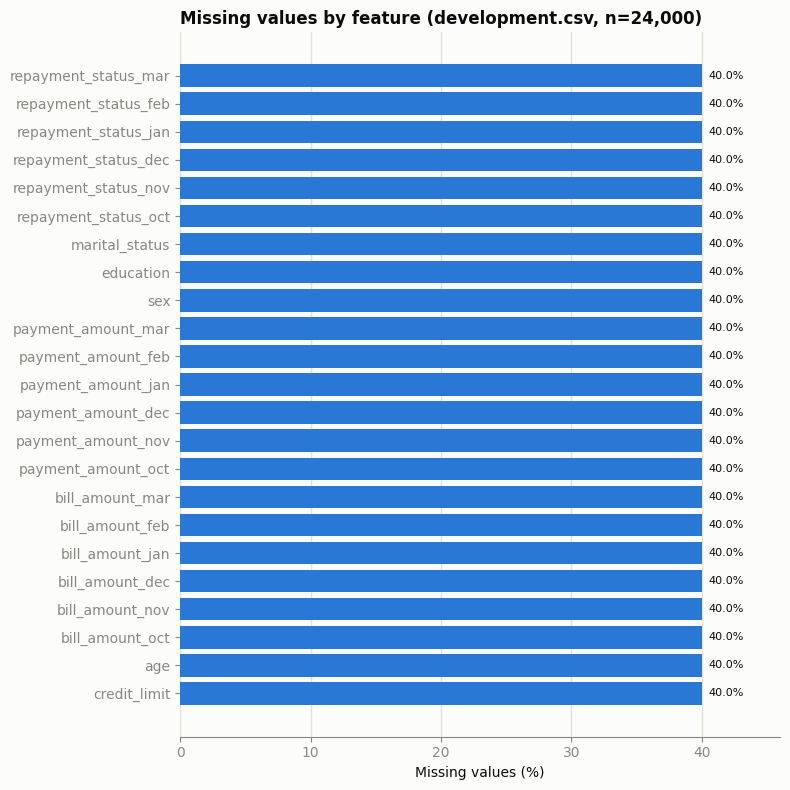

In [18]:
missing_pct = (df[predictor_cols].isnull().sum() / len(df) * 100).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 8))
bars = ax.barh(missing_pct.index, missing_pct.values, color=BLUE, zorder=3)
style_axis(ax, grid_axis='x')
ax.set_xlabel('Missing values (%)')
ax.set_title('Missing values by feature (development.csv, n=24,000)', loc='left', fontweight='bold')
for bar, val in zip(bars, missing_pct.values):
    ax.text(val + 0.5, bar.get_y() + bar.get_height() / 2, f'{val:.1f}%', va='center', fontsize=8, color=INK)
ax.set_xlim(0, max(missing_pct.values) * 1.15)
fig.tight_layout()
plt.show()

**Interpretation:** every one of the 23 predictors is missing at exactly the same rate, 40%.
This uniformity across otherwise unrelated columns (numeric, categorical, and repayment
status alike) points to a missingness mechanism applied independently per column rather than
one driven by the values themselves. This matters for preprocessing: a single global
imputation strategy per feature type (numeric mean/median, categorical mode) is a reasonable
starting point, though we will also test class-conditional imputation to see if the choice
affects downstream F1.

### 2.2 Target class distribution

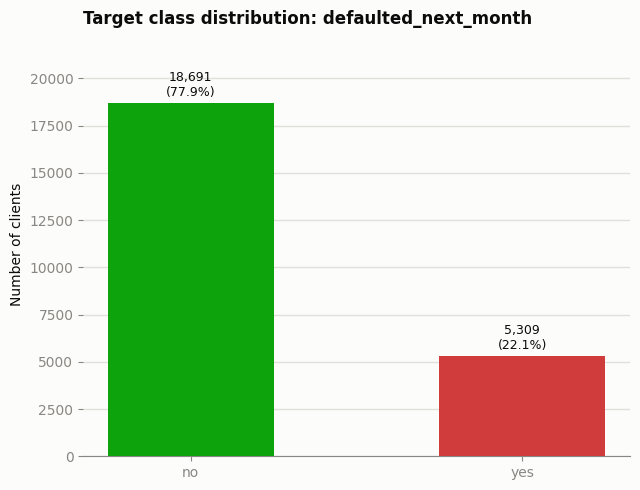

In [19]:
target_counts = df[target_col].value_counts().reindex(['no', 'yes'])
target_pct = (target_counts / target_counts.sum() * 100).round(1)
colors = [GOOD, CRITICAL]

fig, ax = plt.subplots(figsize=(6.5, 5))
bars = ax.bar(target_counts.index, target_counts.values, color=colors, zorder=3, width=0.5)
style_axis(ax, grid_axis='y')
ax.set_ylabel('Number of clients')
ax.set_title('Target class distribution: defaulted_next_month', loc='left', fontweight='bold')
for bar, count, pct in zip(bars, target_counts.values, target_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 200, f'{count:,}\n({pct}%)',
            ha='center', va='bottom', fontsize=9, color=INK)
ax.set_ylim(0, max(target_counts.values) * 1.2)
fig.tight_layout()
plt.show()

**Interpretation:** the classes are imbalanced, 77.9% no-default vs. 22.1% default. A
classifier that always predicts "no" would reach roughly 78% accuracy while catching zero
actual defaults, which is exactly the failure mode accuracy hides and F1 on the positive
class surfaces. This confirms the spec's choice of metric, and it also means stratified
K-fold is required so every fold keeps a similar 78/22 split rather than an accidental
skew toward one class in a given fold.

### 2.3 Numeric feature distributions

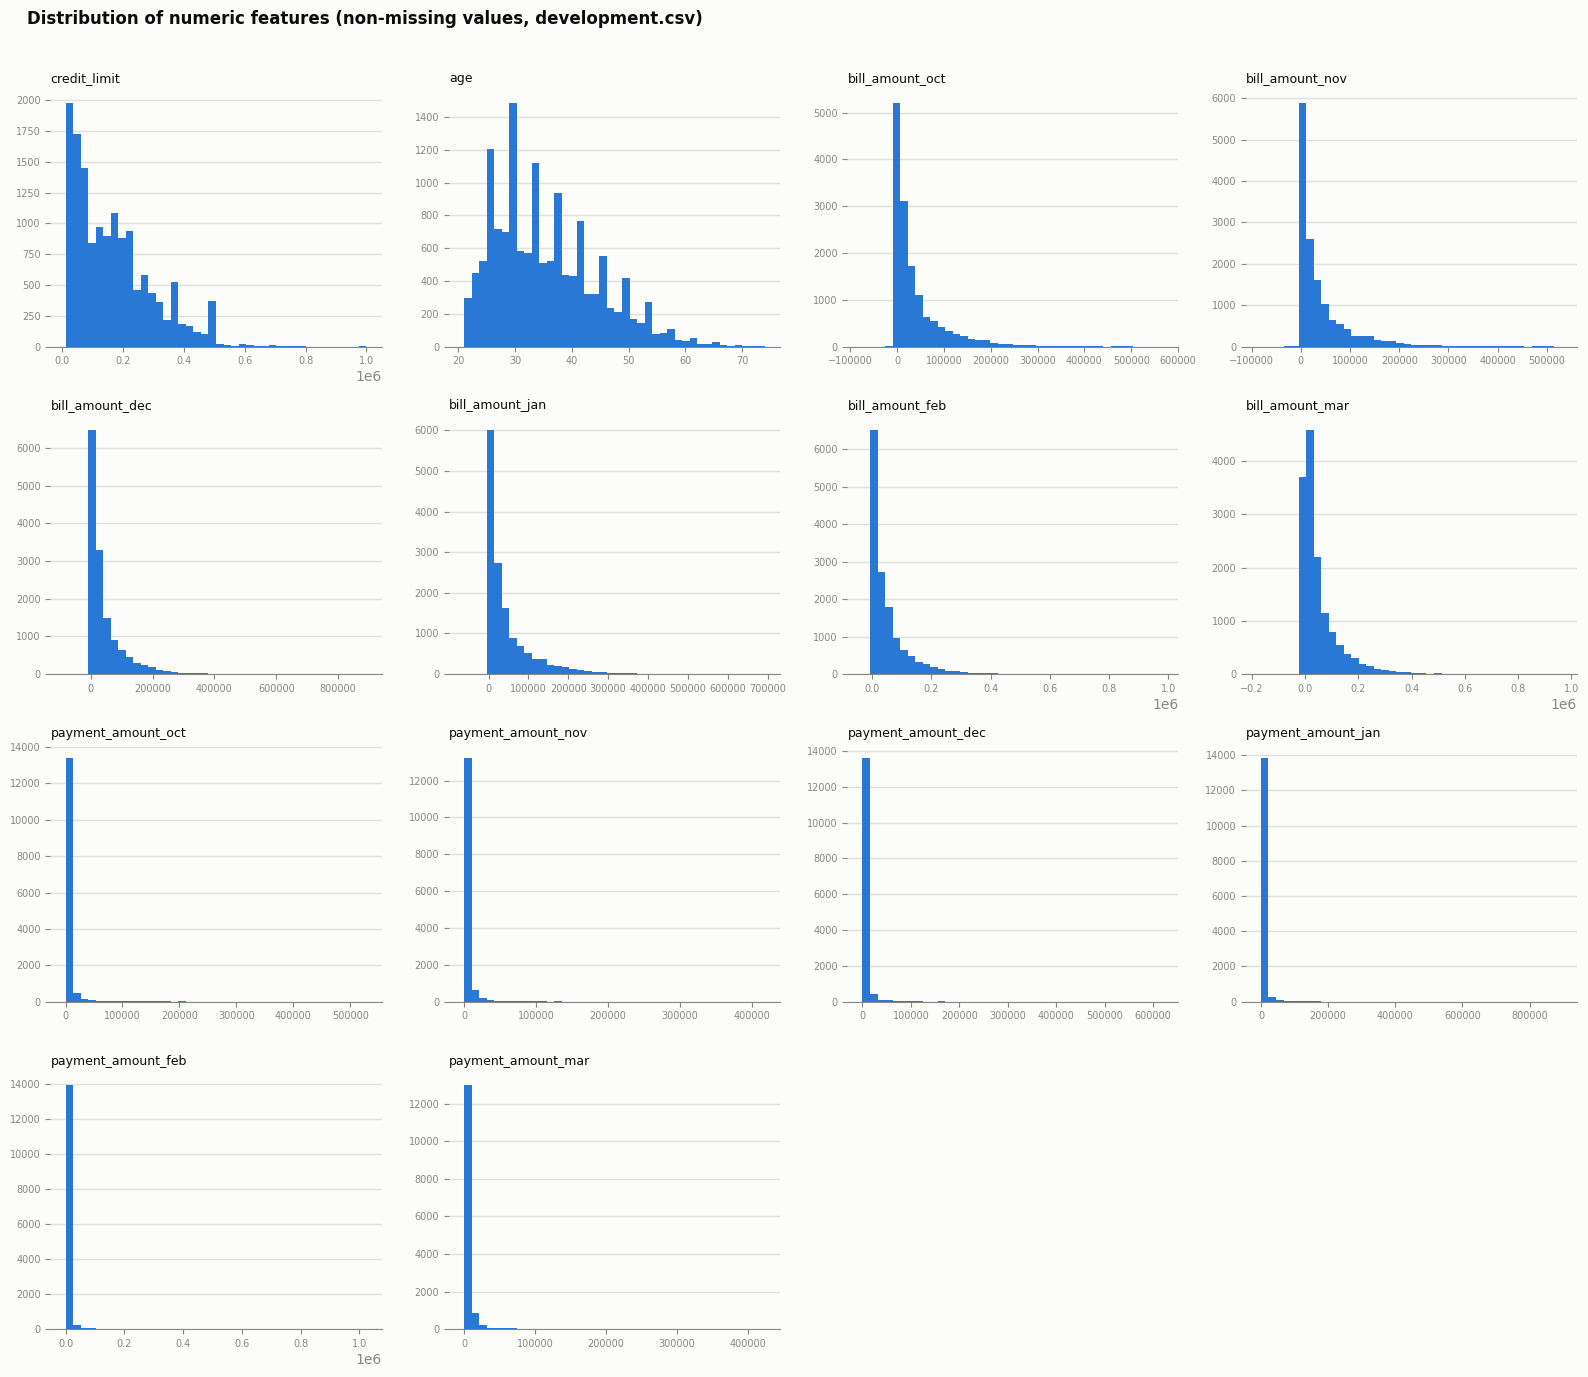

In [20]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    ax = axes[i]
    data = df[col].dropna()
    ax.hist(data, bins=40, color=BLUE, zorder=3)
    style_axis(ax, grid_axis='y')
    ax.set_title(col, fontsize=9, loc='left')
    ax.tick_params(labelsize=7)
for j in range(len(numeric_cols), len(axes)):
    axes[j].set_visible(False)
fig.suptitle('Distribution of numeric features (non-missing values, development.csv)',
             fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

**Interpretation:** `age` is close to a normal-ish shape, while `credit_limit` and every
`bill_amount_*`/`payment_amount_*` column are heavily right-skewed, most values sit near
zero with a long tail out to six figures. `payment_amount_*` is the most extreme case,
almost all mass sits in the first bin. This confirms the concern raised in the project
notes: GaussianNB assumes per-class normality, so these skewed columns are likely to hurt
its performance unless we test a log-transform. It also confirms that scaling will matter
for kNN (features on wildly different scales) but not for the tree-based models.

### 2.4 Categorical feature distributions

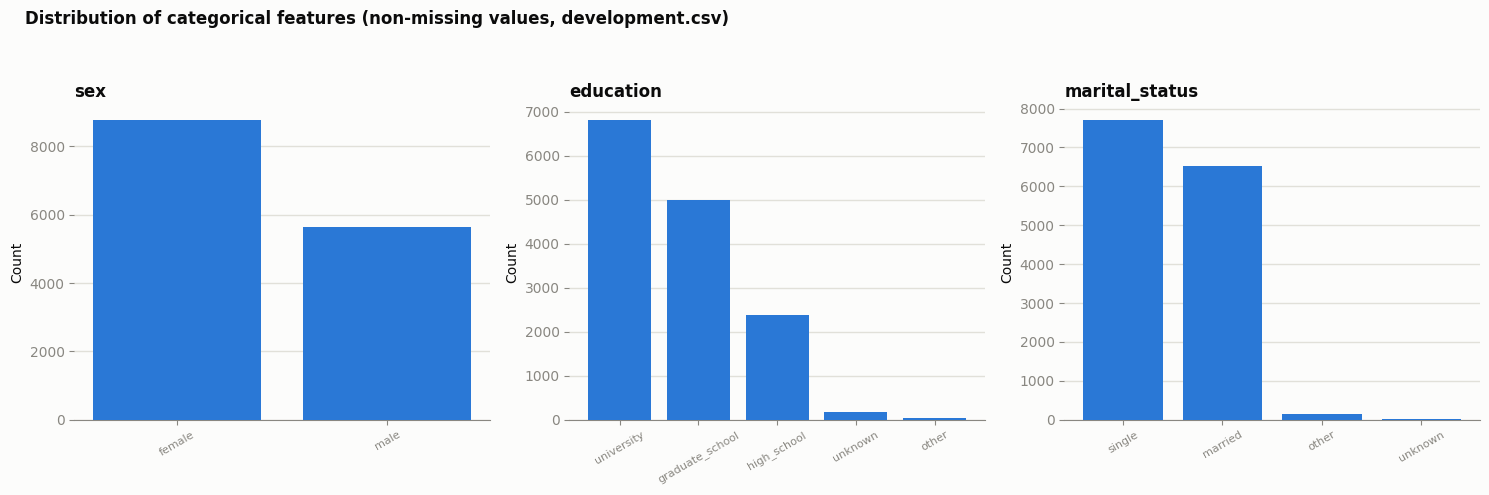

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, col in zip(axes, categorical_cols):
    counts = df[col].value_counts()
    ax.bar(counts.index, counts.values, color=BLUE, zorder=3)
    style_axis(ax, grid_axis='y')
    ax.set_title(col, loc='left', fontweight='bold')
    ax.tick_params(axis='x', rotation=30, labelsize=8)
    ax.set_ylabel('Count')
fig.suptitle('Distribution of categorical features (non-missing values, development.csv)',
             fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

**Interpretation:** `sex` has a moderate imbalance (female > male). `education` and
`marital_status` are each dominated by two or three categories, with `unknown` and `other`
appearing as small residual buckets rather than a meaningful third or fourth class. This
supports one-hot encoding these three columns as-is, since none has an obvious ordering,
while the small residual categories are worth keeping rather than merging, since decision
tree and random forest can split on them cheaply and merging would need a rule decided
without test-set feedback.